# A-FIPI-v1: просмотр 19 задач

19 сохранённых ответов, по одному на задачу. Все 13 требований включены в каждый запрос. Ноутбук пересчитывает анализ без сети и модели. Смысловые оценки основного агента в `reviews.json` — отдельный вход, не экспертный эталон.

Порядок: пересчёт → сводка → три графика → выбранная задача и основания → полный обзор.

In [1]:
from pathlib import Path
import csv, json, html, subprocess, sys
from IPython.display import display, Markdown, Image, HTML
ROOT = Path.cwd()
while not (ROOT / "scripts/analyze_fipi_run.py").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("Откройте ноутбук внутри репозитория")
    ROOT = ROOT.parent
RUN = ROOT / "data/annotation/runs/2026-10-26-A-FIPI-19x1"
TASK_POSITION = 2
print("Корень:", ROOT)
print("Число задач:", 19)

Корень: C:\Users\U_M35CB\Documents\ВШЭ\proactive-ai-tutor-65
Число задач: 19


In [2]:
for script, args in [("scripts/check_fipi_math.py", []), ("scripts/fipi_annotation_run.py", ["capture"]), ("scripts/analyze_fipi_run.py", [])]:
    result = subprocess.run([sys.executable, "-X", "utf8", str(ROOT / script), *args], cwd=ROOT, check=True, capture_output=True, text=True, encoding="utf-8")
summary = json.loads((RUN / "derived/summary.json").read_text(encoding="utf-8"))
display(HTML("<pre>" + html.escape(json.dumps(summary, ensure_ascii=False, indent=2)) + "</pre>"))

## Как читать числа

Количество назначений и буквальность цитаты проверяются кодом. Подходит ли связь к действию, проверял основной агент без ослепления. 11 представленных требований не означают полноту программы. Один ответ на задачу не позволяет оценить стабильность. 79 кандидатов — результат рабочей консервативной канонизации, не число реальных навыков математики.

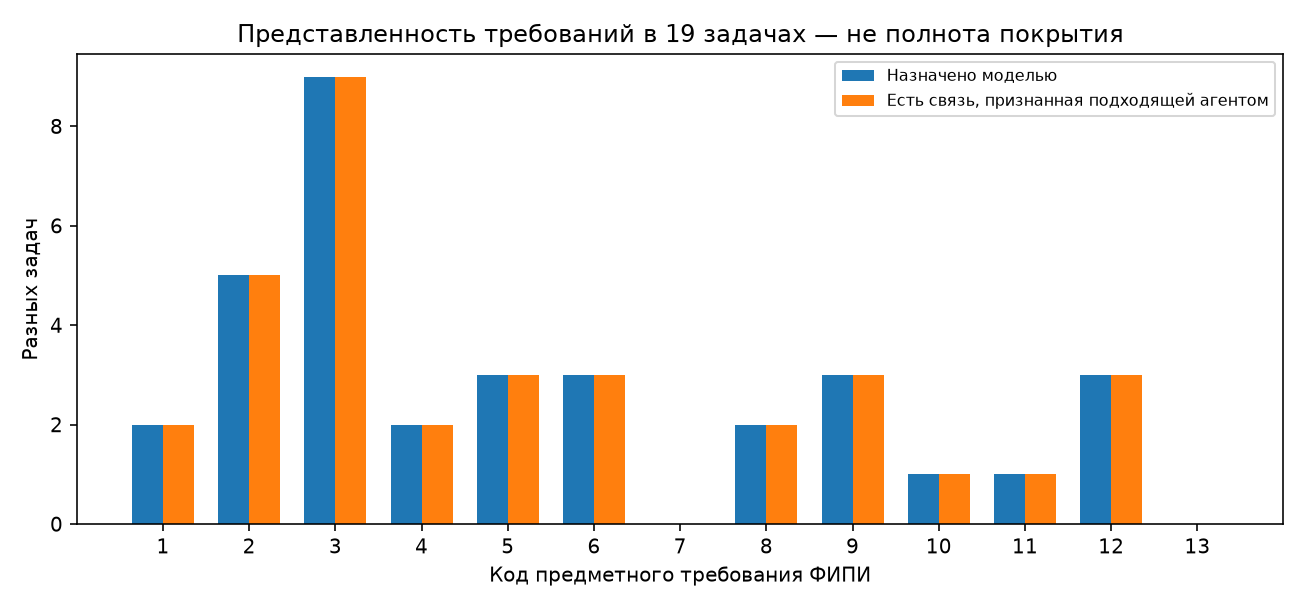

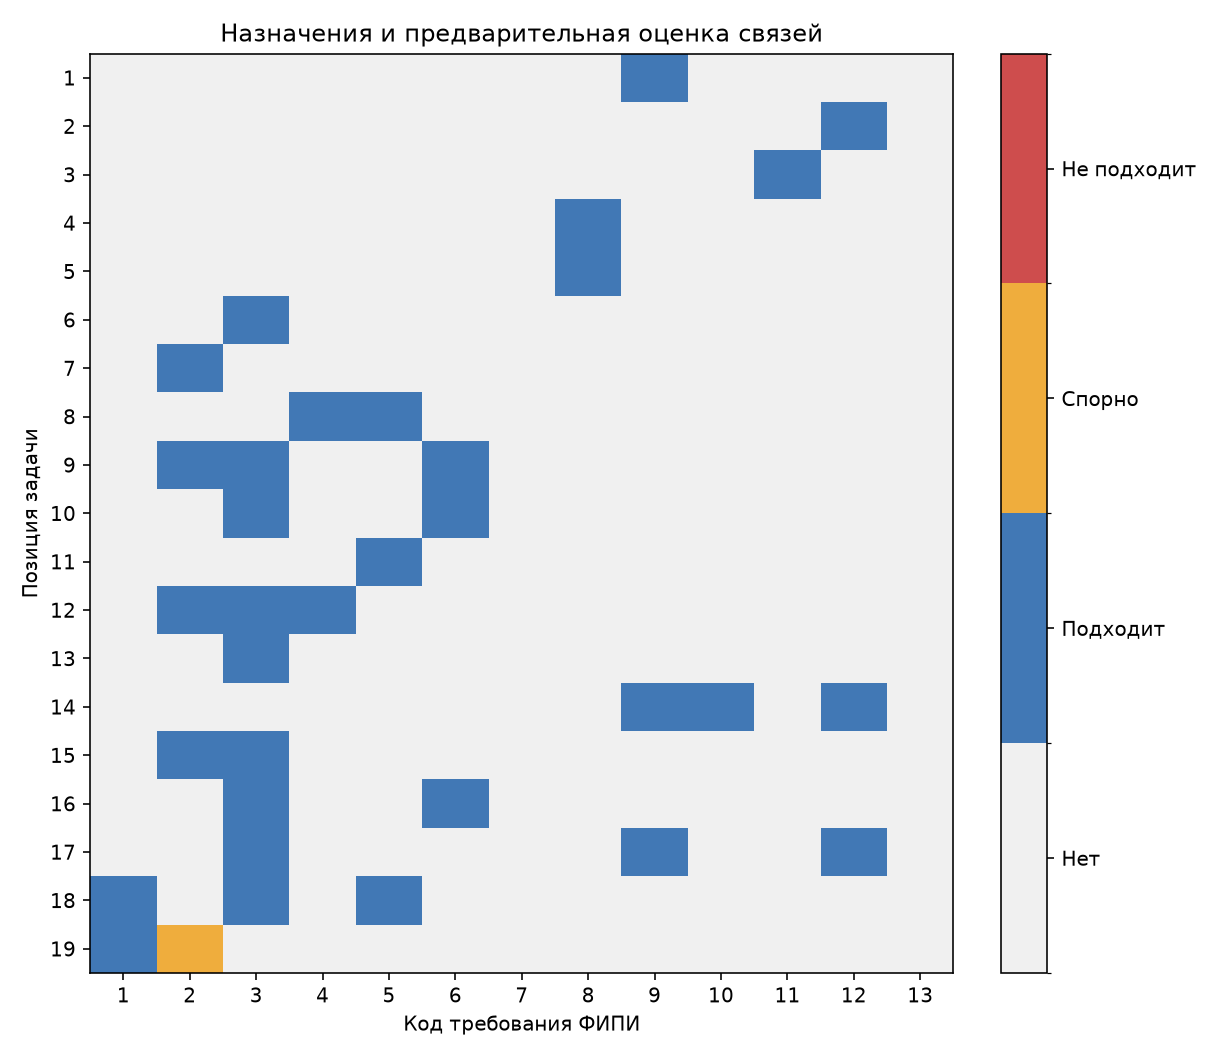

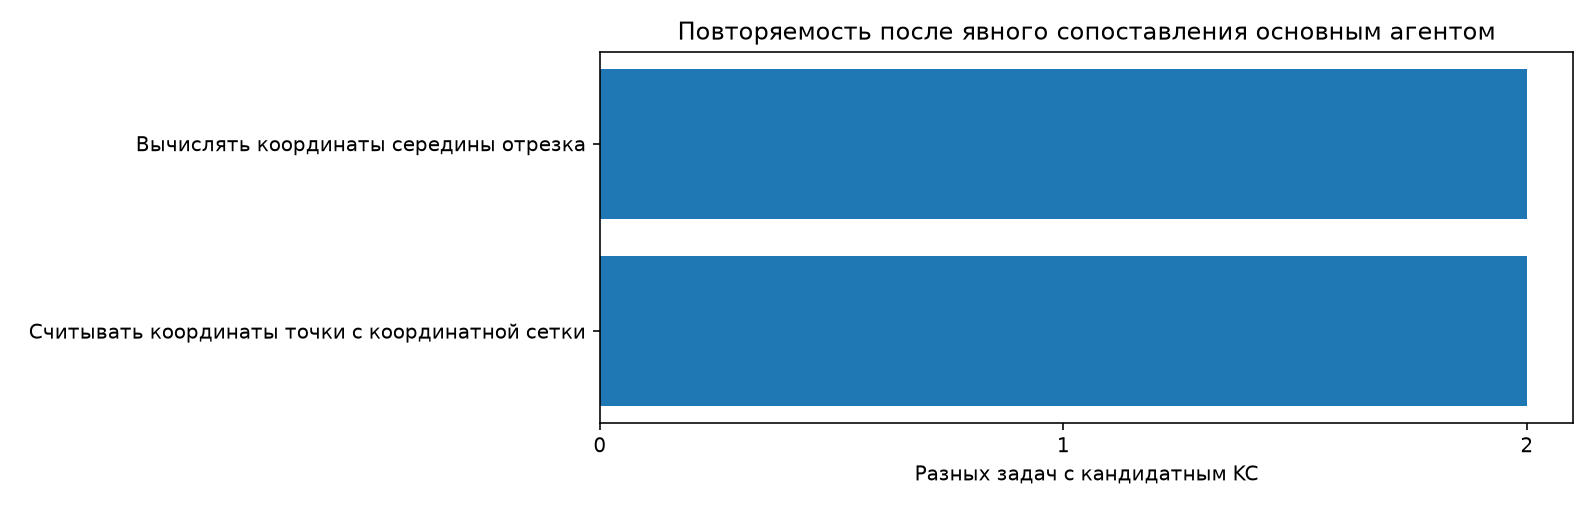

In [3]:
for name in ("requirements", "matrix", "kc-support"):
    display(Image(filename=str(RUN / "derived" / (name + ".png"))))

## №2, 699086

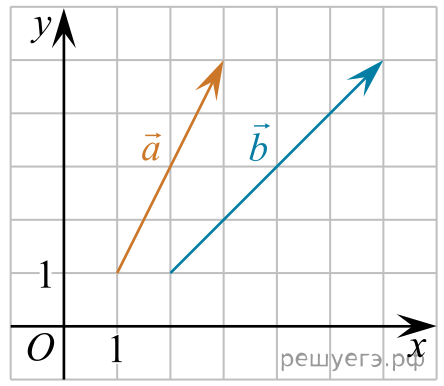

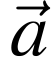

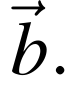

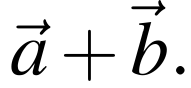

### Исходный ответ

### Предварительная проверка и основания

In [4]:
manifest = json.loads((RUN / "manifest.json").read_text(encoding="utf-8"))
task = next(t for t in manifest["tasks"] if t["position"] == TASK_POSITION)
tid = task["task_id"]
condition = json.loads((RUN / "inputs" / (tid + ".json")).read_text(encoding="utf-8"))
display(Markdown(f"## №{TASK_POSITION}, {tid}"))
display(HTML("<pre>" + html.escape(condition["statement"]) + "</pre>"))
for img in task["images"]:
    display(Image(filename=str(RUN / img["path"])))
raw = json.loads((RUN / "raw" / (tid + ".txt")).read_text(encoding="utf-8"))
review = json.loads((RUN / "reviews.json").read_text(encoding="utf-8"))["tasks"][tid]
for title, value in [("Исходный ответ", raw), ("Предварительная проверка и основания", review)]:
    display(Markdown("### " + title))
    display(HTML("<pre>" + html.escape(json.dumps(value, ensure_ascii=False, indent=2)) + "</pre>"))

In [5]:
display(Markdown((RUN / "interpretation.md").read_text(encoding="utf-8")))
display(Markdown("[Обзор с графиками и таблицей задач](../data/annotation/runs/2026-10-26-A-FIPI-19x1/derived/report.md) · [Все карточки с условиями, ответами и проверкой](../data/annotation/runs/2026-10-26-A-FIPI-19x1/derived/review.html)"))

**На этом наборе схема сверху вниз дала проверяемую классификацию действий по официальной рамке. Единую детализацию и готовую диагностическую карту она пока не дала.**

Назначения представлены в 11 из 13 требований; не назначены коды 7 и 13. Это не означает покрытие 11/13 программы: требование 7 о статистике может отсутствовать из-за состава задач, а общий выбор метода (13) может не выделяться самостоятельным KC. Модель ни разу не выбрала неопределённость, однако один пример связи оценён спорным — отсутствие UNKNOWN не доказывает отсутствие проблем классификации.

Что получилось:

- №8 разделяет чтение графика (требование 5) и применение производной (4); №10 — модель смеси (6) и алгебру (3); №14 — планиметрию (9), построение сечения (10), координатный расчёт (12). Видно, на каком основании задача относится к нескольким классам.
- У каждого назначенного класса есть точная цитата и объяснение модели. Это позволяет проверять связи и обсуждать ошибки, сохраняя происхождение.
- При консервативном просмотре найдены общие кандидатные операции: чтение координат в №2/№11 и середина отрезка в №14/№17. Для чтения координат сохранено отличие более узкого контекста графика. Другие составные определения не объединялись ради повторяемости.

Проблемы и конкретные переходы:

- **№18, s4 → k2:** KC описывает подстановку фиксированной переменной, а в шаге фиксируется параметр и вводится модуль. Назначение помечено спорным. Это проблема соответствия «шаг — KC», а не найденная математическая ошибка.
- **№19, вторая связь ФИПИ:** десятичные переносы, оценка и перебор объединены под цитатой «знакомство с различными позиционными системами счисления». Общая связь понятна, но цитата слишком широка для всей группы действий. Требуется уточнение, а не автоматическое признание верной по совпадению слов.
- **№3:** формулы объёмов размечены, но установление отношения и вычисление по нему отдельно не представлены KC. **№16:** условие общей суммы выплат превращается в уравнение, тогда как назначенный KC описывает исключение неизвестной. Эти два возможных пропуска зависят от принятой детализации и сохранены явно.
- Составность осталась: например, №7:k2 включает тождество и извлечение корня, №12:k3 — знаменатель, квадратное уравнение и отбор; №15:k4 — общую дробь и факторизацию. ФИПИ фиксирует класс, но не выбирает эти границы за нас.

Основной агент просмотрел все рассуждения и отдельно сравнил итоги с сохранёнными ответами источника; явных математических ошибок не обнаружил. Это предварительная проверка, не независимый эталон. Перечни минимальных чисел в №19 дополнительно сверены исчерпывающим локальным перебором (math-check.json), что проверяет только эту часть доказательства.

**Следующий ограниченный шаг:** обсудить две спорные связи и два возможных пропуска, затем зафиксировать правила выбора уровня KC. Не расширять генерацию и не переписывать промпт автоматически. Уменьшение числа сомнений после ручной правки не будет самостоятельным доказательством улучшения модели.


[Обзор с графиками и таблицей задач](../data/annotation/runs/2026-10-26-A-FIPI-19x1/derived/report.md) · [Все карточки с условиями, ответами и проверкой](../data/annotation/runs/2026-10-26-A-FIPI-19x1/derived/review.html)